# Compact benchmark algorithm comparison

This notebook compares **Exhaustive, Greedy, Heuristic, Uniform, and Random** on one-dimensional and two-dimensional datasets generated from unfiltered random field draws.

- **Exhaustive** optimizes over every feasible allocation and every node-specific pair/location decision.
- **Greedy** allocates each sensor where it gives the largest average pairwise error reduction at a location. It builds one local minimum-$P_{ijmn}$ tree after allocation.
- **Heuristic** improves a near-uniform allocation and uses beam search whose partial and complete trees are scored with the exact $P/Q$ branch probabilities.
- **Uniform** uses a near-uniform allocation and a seeded random pair-location tree.
- **Random** provides a seeded random allocation and seeded random pair-location tree.

All methods are evaluated using the final sequential misclassification probability under equal field priors.

In [23]:
# Resolve the project whether Jupyter starts here or from the repository root.
import importlib
from pathlib import Path
import sys
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

working = Path.cwd().resolve()
PROJECT = working / "problem-2-min-error-seq" if (working / "problem-2-min-error-seq").is_dir() else working
SOURCE = PROJECT / "src"
if str(SOURCE) not in sys.path:
    sys.path.insert(0, str(SOURCE))

_analysis_module = importlib.reload(importlib.import_module("analysis"))
run_analysis = _analysis_module.run_analysis
_figures_module = importlib.reload(importlib.import_module("figures"))
save_figures = _figures_module.save_figures
summary_markdown = _figures_module.summary_markdown
allocation_match_table = _figures_module.allocation_match_table
allocation_match_markdown = _figures_module.allocation_match_markdown

## Experimental settings

`test` mode selects **90 cases per spatial dimension**, balanced across field family, $K$, and $M$. `full` mode uses all eligible compact cases. Exhaustive search is restricted by `EXACT_K_MAX`; the compact datasets contain $K\in\{3,4\}$ and $M\in\{3,4\}$.

The time limit applies independently to each method-budget evaluation. Checkpoint reuse is enabled so an interrupted run can continue without recomputing completed records. Progress is printed after every completed case, separately for each dataset.

In [24]:
# Use "full" for the complete study after confirming the test run.
RUN_MODE = "test"
RESUME = True
TIME_LIMIT_SECONDS = 30.0
EXACT_K_MAX = 4

# These controls apply only to the heuristic method.
BEAM_WIDTH = 3
MAX_ITERATIONS = 30

# This notebook is intentionally tied to the compact datasets.
STUDY = "compact"

## Run the matched comparison

Each method is run on the same selected case and sensor-budget combinations. A record is written immediately after each method-budget evaluation. The summary retains only matched combinations completed successfully by every requested method.

In [25]:
# Run or resume the compact comparison with the settings above.
import importlib
run_analysis = importlib.reload(importlib.import_module("analysis")).run_analysis
analysis = run_analysis(
    project=PROJECT,
    study=STUDY,
    mode=RUN_MODE,
    resume=RESUME,
    exact_k_max=EXACT_K_MAX,
    time_limit=TIME_LIMIT_SECONDS,
    beam_width=BEAM_WIDTH,
    max_iterations=MAX_ITERATIONS,
)

# Confirm that this notebook used both compact datasets and all five methods.
expected_datasets = {"compact_benchmark_1d", "compact_benchmark_2d"}
expected_methods = {"Exhaustive", "Greedy", "Heuristic", "Uniform", "Random"}
observed_datasets = {row["dataset"] for row in analysis["rows"]}
observed_methods = {row["method"] for row in analysis["rows"]}
assert observed_datasets == expected_datasets
assert observed_methods == expected_methods
assert {int(row["K"]) for row in analysis["rows"]} == {3, 4}
assert {int(row["M"]) for row in analysis["rows"]} == {3, 4}

case_counts = {
    dimension: len({
        (row["dataset"], row["case"])
        for row in analysis["rows"]
        if int(row["dimension"]) == dimension
    })
    for dimension in (1, 2)
}
if RUN_MODE == "test":
    assert case_counts == {1: 90, 2: 90}

print("Verified datasets:", sorted(observed_datasets))
print("Verified methods:", sorted(observed_methods))
print("Unique cases by dimension:", case_counts)
print("Results directory:", analysis["output"])

compact/test: 180 cases, methods: Exhaustive, Greedy, Heuristic, Uniform, Random
Exact comparison uses K <= 4; limit 30s per method/budget.
compact_benchmark_1d: completed case 1/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 2/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 3/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 4/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 5/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 6/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 7/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 8/90 (gaussian, K=3, M=3)
compact_benchmark_1d: completed case 9/90 (gaussian, K=3, M=4)
compact_benchmark_1d: completed case 10/90 (gaussian, K=3, M=4)
compact_benchmark_1d: completed case 11/90 (gaussian, K=3, M=4)
compact_benchmark_1d: completed case 12/90 (gaussian, K=3, M=4)
compact_benchmark_1d: completed case 13/90 (gaussian, K=3, M=4)
compact_benchmark_1d: completed case 

## Completion and matched summary

The completion counts expose timeouts or missing results before aggregation. The table reports the matched case count, mean budget fraction, mean error probability, mean runtime, and error above Exhaustive where applicable.

In [26]:
# Report method completion before displaying aggregate values.
from collections import Counter

completion = Counter((row["method"], row["status"]) for row in analysis["rows"])
print("Method-status counts:", completion)
display(Markdown(summary_markdown(analysis["summary"])))

Method-status counts: Counter({('Exhaustive', 'ok'): 710, ('Greedy', 'ok'): 710, ('Heuristic', 'ok'): 710, ('Uniform', 'ok'): 710, ('Random', 'ok'): 710})


| Dimension | Budget | Method | Cases | Mean Error Probability | Mean Time (s) | Mean Gap |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 1 | Exhaustive | 90 | 0.30612 | 0.0527 | 0.00000 |
| One-dimensional | 1 | Greedy | 90 | 0.43547 | 0.0003 | 0.12935 |
| One-dimensional | 1 | Heuristic | 90 | 0.31072 | 0.0009 | 0.00460 |
| One-dimensional | 1 | Random | 90 | 0.62073 | 0.0002 | 0.31461 |
| One-dimensional | 1 | Uniform | 90 | 0.59980 | 0.0002 | 0.29368 |
| One-dimensional | 2 | Exhaustive | 90 | 0.15079 | 0.3055 | 0.00000 |
| One-dimensional | 2 | Greedy | 90 | 0.33879 | 0.0004 | 0.18800 |
| One-dimensional | 2 | Heuristic | 90 | 0.16224 | 0.0011 | 0.01146 |
| One-dimensional | 2 | Random | 90 | 0.54742 | 0.0002 | 0.39664 |
| One-dimensional | 2 | Uniform | 90 | 0.53195 | 0.0002 | 0.38116 |
| One-dimensional | 3 | Exhaustive | 89 | 0.07007 | 0.9322 | 0.00000 |
| One-dimensional | 3 | Greedy | 89 | 0.24415 | 0.0004 | 0.17407 |
| One-dimensional | 3 | Heuristic | 89 | 0.07784 | 0.0013 | 0.00777 |
| One-dimensional | 3 | Random | 89 | 0.45074 | 0.0002 | 0.38066 |
| One-dimensional | 3 | Uniform | 89 | 0.45844 | 0.0002 | 0.38837 |
| One-dimensional | 4 | Exhaustive | 85 | 0.04105 | 2.0298 | 0.00000 |
| One-dimensional | 4 | Greedy | 85 | 0.19394 | 0.0005 | 0.15290 |
| One-dimensional | 4 | Heuristic | 85 | 0.04348 | 0.0015 | 0.00243 |
| One-dimensional | 4 | Random | 85 | 0.41353 | 0.0002 | 0.37248 |
| One-dimensional | 4 | Uniform | 85 | 0.38379 | 0.0002 | 0.34274 |
| Two-dimensional | 1 | Exhaustive | 90 | 0.35500 | 0.0535 | 0.00000 |
| Two-dimensional | 1 | Greedy | 90 | 0.43953 | 0.0003 | 0.08453 |
| Two-dimensional | 1 | Heuristic | 90 | 0.36120 | 0.0008 | 0.00621 |
| Two-dimensional | 1 | Random | 90 | 0.61173 | 0.0002 | 0.25673 |
| Two-dimensional | 1 | Uniform | 90 | 0.62515 | 0.0002 | 0.27015 |
| Two-dimensional | 2 | Exhaustive | 90 | 0.19692 | 0.2758 | 0.00000 |
| Two-dimensional | 2 | Greedy | 90 | 0.33729 | 0.0003 | 0.14037 |
| Two-dimensional | 2 | Heuristic | 90 | 0.21159 | 0.0010 | 0.01467 |
| Two-dimensional | 2 | Random | 90 | 0.56184 | 0.0002 | 0.36492 |
| Two-dimensional | 2 | Uniform | 90 | 0.56998 | 0.0002 | 0.37306 |
| Two-dimensional | 3 | Exhaustive | 90 | 0.11281 | 0.8458 | 0.00000 |
| Two-dimensional | 3 | Greedy | 90 | 0.27506 | 0.0004 | 0.16224 |
| Two-dimensional | 3 | Heuristic | 90 | 0.12515 | 0.0012 | 0.01234 |
| Two-dimensional | 3 | Random | 90 | 0.50582 | 0.0002 | 0.39301 |
| Two-dimensional | 3 | Uniform | 90 | 0.50596 | 0.0002 | 0.39315 |
| Two-dimensional | 4 | Exhaustive | 86 | 0.07435 | 1.9013 | 0.00000 |
| Two-dimensional | 4 | Greedy | 86 | 0.22247 | 0.0005 | 0.14812 |
| Two-dimensional | 4 | Heuristic | 86 | 0.08517 | 0.0015 | 0.01082 |
| Two-dimensional | 4 | Random | 86 | 0.47242 | 0.0002 | 0.39807 |
| Two-dimensional | 4 | Uniform | 86 | 0.46641 | 0.0002 | 0.39206 |

## Allocation agreement and comparison figures

Allocation agreement is reported in a table by dimension and $K$ for Greedy–Heuristic and Greedy–Exhaustive. A plot is omitted for the compact study. The figures show **mean error probability versus mean budget fraction** and mean error by field family. Field-family results use grouped mean bars with 95% confidence intervals. The compact runtime figure is omitted. Total-budget agreement is omitted because every method receives the same fixed $N$. All results use the same matched samples.

### Allocation Match Statistics

| Dimension | K | Comparison | Matches | Runs | Match (%) | 95% CI |
|---|---:|---|---:|---:|---:|---:|
| One-dimensional | 3 | Greedy–Heuristic | 14 | 178 | 7.9 | [3.9, 11.8] |
| One-dimensional | 3 | Greedy–Exhaustive | 14 | 178 | 7.9 | [3.9, 11.8] |
| One-dimensional | 4 | Greedy–Heuristic | 4 | 176 | 2.3 | [0.1, 4.5] |
| One-dimensional | 4 | Greedy–Exhaustive | 3 | 176 | 1.7 | [0.0, 3.6] |
| Two-dimensional | 3 | Greedy–Heuristic | 27 | 180 | 15.0 | [9.8, 20.2] |
| Two-dimensional | 3 | Greedy–Exhaustive | 28 | 180 | 15.6 | [10.2, 20.9] |
| Two-dimensional | 4 | Greedy–Heuristic | 15 | 176 | 8.5 | [4.4, 12.7] |
| Two-dimensional | 4 | Greedy–Exhaustive | 20 | 176 | 11.4 | [6.7, 16.1] |

### Error Probability

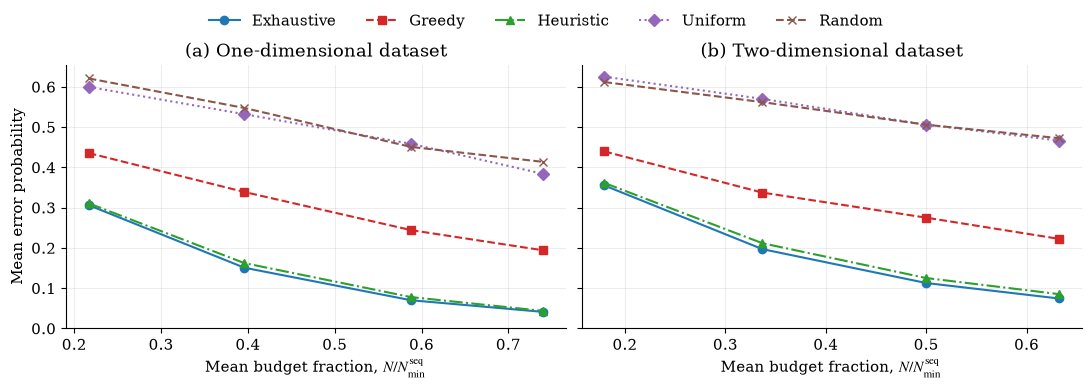

### Error By Field Family

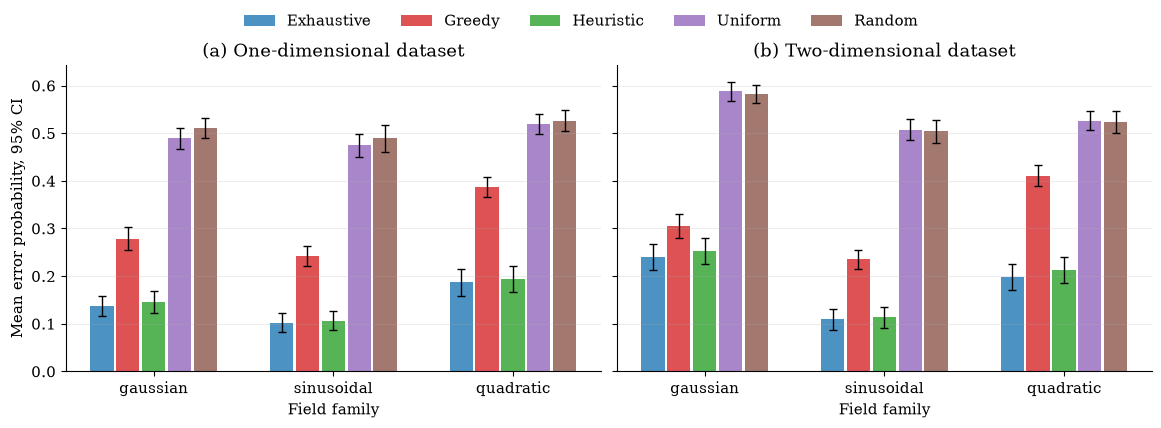

In [27]:
# Save the allocation table and publication-quality figures, then display them.
_figures_module = importlib.reload(importlib.import_module("figures"))
save_figures = _figures_module.save_figures
allocation_match_table = _figures_module.allocation_match_table
allocation_match_markdown = _figures_module.allocation_match_markdown
if not analysis["summary"]:
    raise RuntimeError("No matched completed cases are available for plotting")

allocation_stats = allocation_match_table(analysis["rows"])
_analysis_module.write_csv(
    analysis["output"] / "tables" / "allocation_match.csv",
    allocation_stats,
)
display(Markdown("### Allocation Match Statistics"))
display(Markdown(allocation_match_markdown(allocation_stats)))

figures = save_figures(
    analysis["summary"],
    analysis["rows"],
    analysis["output"],
)
for name, figure in figures.items():
    display(Markdown(f"### {name.replace('_', ' ').title()}"))
    display(figure)
    plt.close(figure)
